In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully!")


c:\Users\ABDUL MAHROOF N\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Libraries imported successfully!


In [2]:

possible_paths = list(Path("data").glob("*.csv"))
possible_paths += list(Path(".").glob("*.csv"))

if not possible_paths:
    from google.colab import files
    uploaded = files.upload()
    csv_path = Path(next(iter(uploaded)))
else:
    csv_path = possible_paths[0]

df = pd.read_csv(csv_path)

print("Dataset loaded:", csv_path.name)
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded: Laptop_price.csv
Dataset shape: (1000, 7)


,Brand,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight,Price
0,Asus,3.830296,16,512,11.185147,2.641094,17395.093065
1,Acer,2.912833,4,1000,11.311372,3.260012,31607.605919
2,Lenovo,3.241627,4,256,11.853023,2.029061,9291.023542
3,Acer,3.806248,16,512,12.280360,4.573865,17436.728334
4,Acer,3.268097,32,1000,14.990877,4.193472,32917.990718


In [3]:

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Columns:", df.columns.tolist())
display(df.head())


Columns: ['brand', 'processor_speed', 'ram_size', 'storage_capacity', 'screen_size', 'weight', 'price']


,brand,processor_speed,ram_size,storage_capacity,screen_size,weight,price
0,Asus,3.830296,16,512,11.185147,2.641094,17395.093065
1,Acer,2.912833,4,1000,11.311372,3.260012,31607.605919
2,Lenovo,3.241627,4,256,11.853023,2.029061,9291.023542
3,Acer,3.806248,16,512,12.280360,4.573865,17436.728334
4,Acer,3.268097,32,1000,14.990877,4.193472,32917.990718


In [4]:

print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("data_type"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("missing_values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe().T)


Shape: (1000, 7)

Data types:


,data_type
brand,object
processor_speed,float64
ram_size,int64
storage_capacity,int64
screen_size,float64
weight,float64
price,float64



Missing values:


,missing_values
brand,0
processor_speed,0
ram_size,0
storage_capacity,0
screen_size,0
weight,0
price,0



Duplicate rows: 0

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
processor_speed,1000.0,2.750611,0.731796,1.511580,2.089246,2.760885,3.362610,3.998534
ram_size,1000.0,15.500000,10.988665,4.000000,8.000000,16.000000,32.000000,32.000000
storage_capacity,1000.0,584.576000,313.438517,256.000000,256.000000,512.000000,1000.000000,1000.000000
screen_size,1000.0,14.056790,1.705882,11.012111,12.635523,14.099643,15.528590,16.985737
weight,1000.0,3.466919,0.866541,2.000560,2.717211,3.464630,4.212583,4.990728
price,1000.0,19604.187963,9406.064880,8570.012950,10114.012948,17287.241878,31566.214754,33503.935037


In [5]:

df = df.drop_duplicates().copy()

# Convert numerical columns where possible
numeric_candidates = [
    "processor_speed", "ram_size", "storage",
    "screen_size", "weight", "price"
]

for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col].astype(str).str.replace(",", "", regex=False)
            .str.extract(r"([-+]?\d*\.?\d+)")[0],
            errors="coerce"
        )

print("Shape after removing duplicates:", df.shape)
print("\nMissing values after conversion:")
display(df.isnull().sum().to_frame("missing_values"))


Shape after removing duplicates: (1000, 7)

Missing values after conversion:


,missing_values
brand,0
processor_speed,0
ram_size,0
storage_capacity,0
screen_size,0
weight,0
price,0


In [6]:

for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

if "brand" in df.columns:
    df["brand"] = df["brand"].fillna("Unknown")

print("Remaining missing values:", int(df.isnull().sum().sum()))


Remaining missing values: 0


In [7]:

for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

if "brand" in df.columns:
    df["brand"] = df["brand"].fillna("Unknown")

print("Remaining missing values:", int(df.isnull().sum().sum()))


Remaining missing values: 0


c:\Users\ABDUL MAHROOF N\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


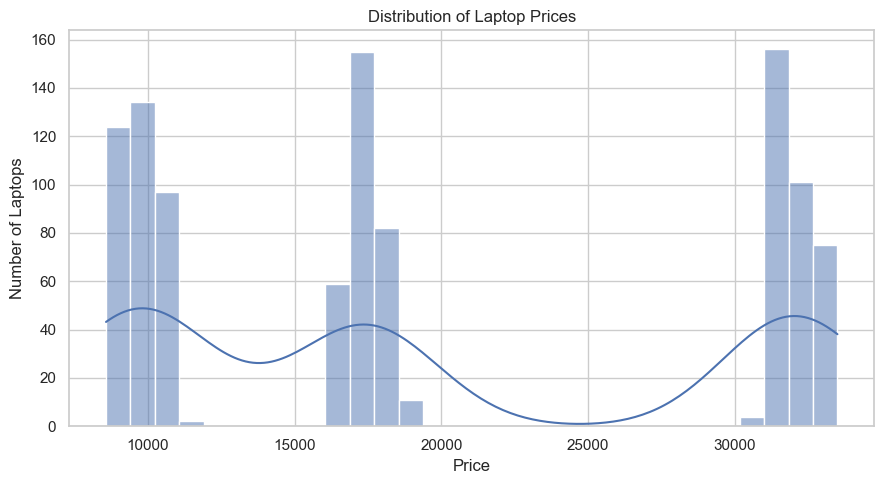

In [8]:

plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="price", bins=30, kde=True)
plt.title("Distribution of Laptop Prices")
plt.xlabel("Price")
plt.ylabel("Number of Laptops")
plt.tight_layout()
plt.savefig(FIG_DIR / "price_distribution.png", dpi=150)
plt.show()


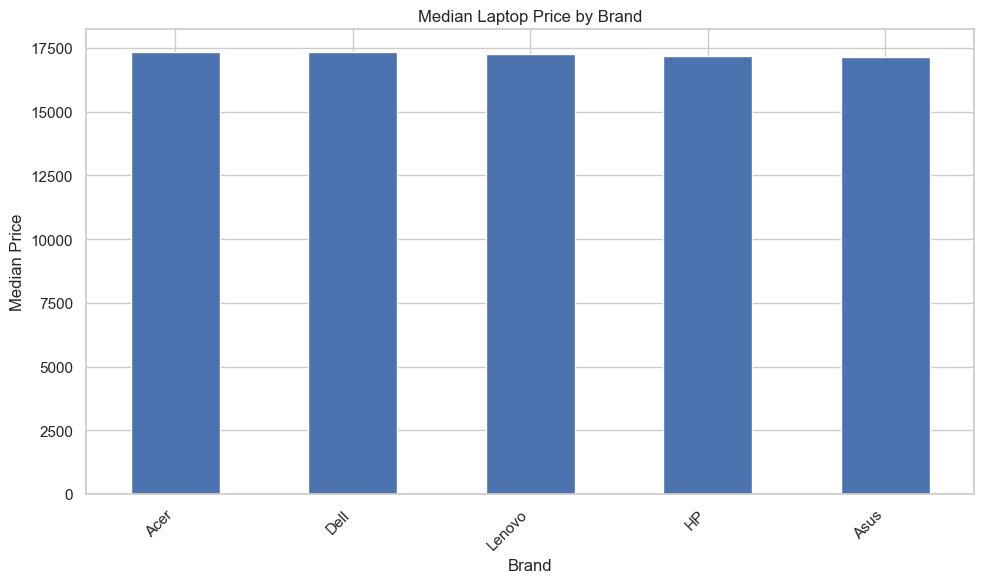

,median_price
brand,
Acer,17353.422280
Dell,17324.818675
Lenovo,17257.951912
HP,17184.622587
Asus,17157.372443


In [9]:

brand_prices = (
    df.groupby("brand")["price"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
brand_prices.plot(kind="bar")
plt.title("Median Laptop Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Median Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "price_by_brand.png", dpi=150)
plt.show()

display(brand_prices.to_frame("median_price"))


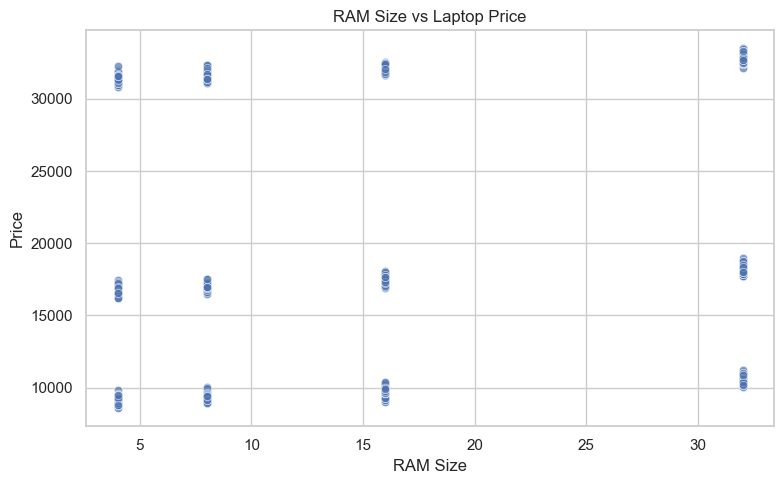

In [10]:

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="ram_size", y="price", alpha=0.7)
plt.title("RAM Size vs Laptop Price")
plt.xlabel("RAM Size")
plt.ylabel("Price")
plt.tight_layout()
plt.savefig(FIG_DIR / "ram_vs_price.png", dpi=150)
plt.show()


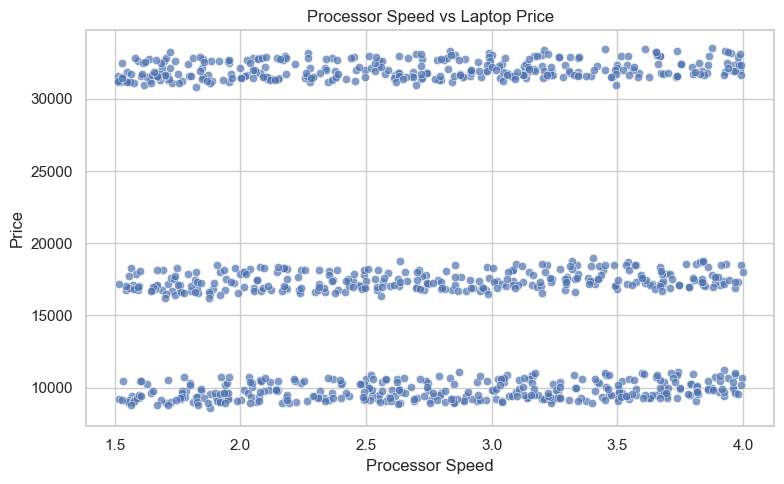

In [11]:

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="processor_speed", y="price", alpha=0.7)
plt.title("Processor Speed vs Laptop Price")
plt.xlabel("Processor Speed")
plt.ylabel("Price")
plt.tight_layout()
plt.savefig(FIG_DIR / "processor_vs_price.png", dpi=150)
plt.show()


In [12]:

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="storage", y="price", alpha=0.7)
plt.title("Storage Capacity vs Laptop Price")
plt.xlabel("Storage")
plt.ylabel("Price")
plt.tight_layout()
plt.savefig(FIG_DIR / "storage_vs_price.png", dpi=150)
plt.show()


ValueError: Could not interpret value `storage` for parameter `x`

<Figure size 800x500 with 0 Axes>

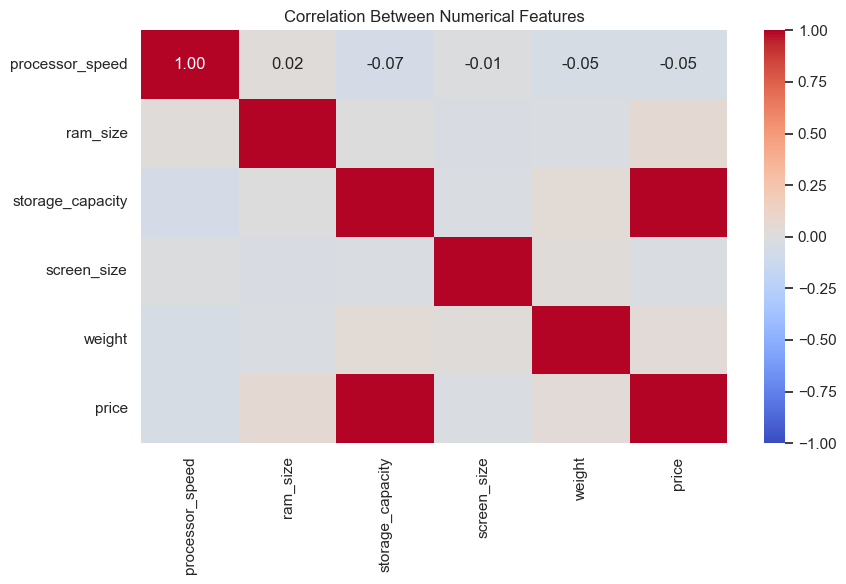

In [13]:

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(9, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=150)
plt.show()


In [14]:

print("LAPTOP PRICE EDA SUMMARY")
print("=" * 35)
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Number of brands:", df["brand"].nunique())
print("Median laptop price:", round(df["price"].median(), 2))
print("Average laptop price:", round(df["price"].mean(), 2))
print("Lowest price:", round(df["price"].min(), 2))
print("Highest price:", round(df["price"].max(), 2))

print("\nMedian price by brand:")
display(
    df.groupby("brand")["price"]
    .median()
    .sort_values(ascending=False)
    .round(2)
)

print("\nCorrelation with price:")
display(
    numeric_df.corr()["price"]
    .drop("price")
    .sort_values(ascending=False)
    .to_frame("correlation_with_price")
)


LAPTOP PRICE EDA SUMMARY
Total rows: 1000
Total columns: 7
Number of brands: 5
Median laptop price: 17287.24
Average laptop price: 19604.19
Lowest price: 8570.01
Highest price: 33503.94

Median price by brand:


brand
Acer      17353.42
Dell      17324.82
Lenovo    17257.95
HP        17184.62
Asus      17157.37
Name: price, dtype: float64


Correlation with price:


,correlation_with_price
storage_capacity,0.997908
ram_size,0.061237
weight,0.038417
screen_size,-0.026740
processor_speed,-0.050737
